# Probabilistic FDM — 非線形楕円型 PDE (Chen et al. 2021 と同じ設定)

PDE: $-\Delta u + u^3 = f$, $(x,y) \in (0,1)^2$, $u=0$ on $\partial(0,1)^2$

prescribed solution: $u^*(x,y) = \sin(\pi x)\sin(\pi y) + 4\sin(4\pi x)\sin(4\pi y)$

観測モデル: $f = \mathcal{F}(u) + \epsilon$, $\mathcal{F}(u) = D_h u + u^3$ (非線形！)

Laplace 近似:
1. MAP 推定: $\hat{u} = \arg\min [\|u\|^2_{K^{-1}} + \|\mathcal{F}(u) - f\|^2_{\Sigma^{-1}}]$ (Newton 法)
2. 事後分散: $\Sigma^{\text{post}} = K - KJ^\top(JKJ^\top + \Sigma)^{-1}JK$ (Jacobian で線形化)

**Chen et al. (2021) との違い: 同じ PDE・prescribed solution を使用するが，提案手法はさらに事後分散による UQ を提供する。**


In [1]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics
using SparseArrays
using Printf
println("Packages loaded.")


Packages loaded.


In [2]:
# 1次元 Matérnカーネル
function matern_kernel_1d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_1d(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = length(X1), length(X2)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_1d(X1[i], X2[j]; ν=ν, ℓ=ℓ, σf=σf)
    end
    return K
end
println("1D Kernel defined.")


1D Kernel defined.


In [3]:
# ============================================================
# グリッド設定 + 解析解
# ============================================================
function make_grid_1d(Nx)
    dx  = 1.0 / (Nx + 1)
    # 全点（境界含む）: x_0=0, x_1, ..., x_Nx, x_{Nx+1}=1
    x_all = [dx*i for i in 0:Nx+1]
    # 内点インデックス (Juliaは1始まりなので2:Nx+1)
    return dx, x_all, Nx+2  # N_total = Nx+2
end

# prescribed solution
u_true(x)    = sin(pi*x) + 0.5*sin(4*pi*x)
neg_lap_u(x) = pi^2*sin(pi*x) + 0.5*(4*pi)^2*sin(4*pi*x)
f_rhs(x)     = neg_lap_u(x) + u_true(x)^3

println("Grid and analytical solution defined.")


Grid and analytical solution defined.


In [4]:
# ============================================================
# 情報作用素 (全点ベクトル版)
# u = (u_0, u_1, ..., u_Nx, u_{Nx+1}) ∈ R^{Nx+2}
#
# D_h: 内点では -Delta_h，境界では恒等写像
# Sigma: 内点では C*h^{2tau}，境界では 0 (ノイズなし観測)
# ============================================================
function make_Dh_1d(Nx, dx)
    N = Nx + 2  # 全点数
    D = zeros(N, N)
    # 境界点: 恒等写像
    D[1,1]     = 1.0
    D[end,end] = 1.0
    # 内点: -Delta_h
    for i in 2:N-1
        D[i,i-1] = -1.0/dx^2
        D[i,i]   =  2.0/dx^2
        D[i,i+1] = -1.0/dx^2
    end
    return D
end

function make_Sigma(Nx, dx; C=1.0, tau=2)
    N = Nx + 2
    noise_var  = C * dx^(2*tau)
    # 境界点はノイズゼロ，内点はC*h^{2tau}
    diag_vals  = [i==1 || i==N ? 0.0 : noise_var for i in 1:N]
    return Diagonal(diag_vals)
end

# 非線形情報作用素: F(u) = D_h*u + [0, u_int^3..., 0]
function nonlinear_F(u, Dh)
    N   = length(u)
    Fu  = Dh * u
    # 非線形項は内点のみ
    Fu[2:N-1] .+= u[2:N-1].^3
    return Fu
end

# Jacobian: J(u) = D_h + diag(0, 3u_int^2..., 0)
function jacobian_F(u, Dh)
    N    = length(u)
    diag_nl = zeros(N)
    diag_nl[2:N-1] = 3*u[2:N-1].^2
    return Dh + Diagonal(diag_nl)
end

println("Dh and nonlinear operators defined.")


Dh and nonlinear operators defined.


In [11]:
# ============================================================
# 通常の FDM 解 (Newton 法)
# ============================================================
function newton_fdm(dx, Nx, f_all; tol=1e-10, maxiter=100)
    Dh = make_Dh_1d(Nx, dx)
    N  = Nx + 2
    u  = zeros(N)
    for it in 1:maxiter
        F  = nonlinear_F(u, Dh) - f_all
        J  = jacobian_F(u, Dh)
        du = J \ (-F)
        u .+= du
        if norm(du) < tol
            println("  FDM Newton converged at iter $(it)")
            break
        end
    end
    return u
end

# MAP推定のNewton法
function newton_map(dx, Nx, f_all, K; C=1.0, tau=2, tol=1e-10, maxiter=100)
    Dh        = make_Dh_1d(Nx, dx)
    Sigma     = make_Sigma(Nx, dx; C=C, tau=tau)
    # 境界点でのSigma_invは無限大なので，境界を別扱い
    # 境界点: Sigma_ii = 0 → 完全観測として扱う
    # 内点:   Sigma_ii = C*h^{2tau}
    N         = Nx + 2
    noise_var = C * dx^(2*tau)
    # Sigma_inv: 境界は大きな値，内点は1/noise_var
    sigma_inv_diag = [i==1||i==N ? 1e10 : 1.0/noise_var for i in 1:N]
    Sigma_inv = Diagonal(sigma_inv_diag)
    K_inv     = inv(Matrix(K) + 1e-8*I)

    u = zeros(N)
    for it in 1:maxiter
        F_val = nonlinear_F(u, Dh) - f_all
        J     = jacobian_F(u, Dh)
        H     = J' * Sigma_inv * J + K_inv
        g     = J' * Sigma_inv * F_val + K_inv * u
        du    = H \ (-g)
        u .+= du
        if norm(du) < tol
            println("  MAP Newton converged at iter $(it)")
            break
        end
    end
    return u
end

println("Newton functions defined.")


Newton functions defined.


In [12]:
# ============================================================
# Laplace 近似
# ============================================================
function laplace_posterior(u_map, dx, Nx, K; C=1.0, tau=2)
    N         = Nx + 2
    Dh        = make_Dh_1d(Nx, dx)
    J         = jacobian_F(u_map, Dh)
    noise_var = C * dx^(2*tau)
    sigma_inv_diag = [i==1||i==N ? 1e10 : 1.0/noise_var for i in 1:N]
    Sigma_inv = Diagonal(sigma_inv_diag)
    # Sigma_noise for GP regression
    sigma_diag = [i==1||i==N ? 1e-10 : noise_var for i in 1:N]
    Sigma_noise = Diagonal(sigma_diag)

    JK  = J * K
    M   = Symmetric(JK * J' + Sigma_noise + 1e-10*I)
    L   = cholesky(M).L

    mu_post  = u_map
    V        = L \ JK
    Sig_post = K - V' * V
    std_post = sqrt.(max.(diag(Sig_post), 0.0))

    return mu_post, std_post
end

println("laplace_posterior defined.")


laplace_posterior defined.


In [20]:
# ============================================================
# Grid search (y = f_all ~ O(1) を観測として使用)
# 情報作用素: D_h (線形部分のみ) → Poissonと同じ構造
# ============================================================

function log_mll_1d(f_all, dx, Nx, K; C=1.0, tau=2)
    N           = Nx + 2
    Dh          = make_Dh_1d(Nx, dx)
    sigma_diag  = [i==1||i==N ? 1e-10 : C*dx^(2*tau) for i in 1:N]
    Sigma_noise = Diagonal(sigma_diag)

    # y = f_all ~ O(1) (Poissonと同じ構造)
    y   = f_all
    DhK = Dh * K
    M   = Symmetric(DhK * Dh' + Sigma_noise + 1e-10*I)
    try
        L     = cholesky(M).L
        alpha = L' \ (L \ y)
        return -0.5*dot(y, alpha) - sum(log.(diag(L))) - 0.5*N*log(2*pi)
    catch
        return -Inf
    end
end

function grid_search_1d(f_all, x_all, dx, Nx;
                         tau=2, nu_ker=1.5, σf_fixed=0.5)
    ℓ_grid = 10.0 .^ range(-2, 1, length=8)
    C_grid = 10.0 .^ range(-3, 2, length=8)

    best_lml = -Inf
    best_l   = 0.5
    best_C   = 1.0

    println("\n=== Marginal likelihood table (σf=$(round(σf_fixed,digits=3)) fixed) ===")
    @printf("%-12s", "l \\ C")
    for C in C_grid
        @printf("%-11s", "$(round(C,sigdigits=2))")
    end
    println()
    println("-"^(12 + 11*length(C_grid)))

    for l in ℓ_grid
        @printf("%-12s", "$(round(l,sigdigits=2))")
        for C in C_grid
            K_cand = Symmetric(kernel_matrix_1d(x_all, x_all; ν=nu_ker, ℓ=l, σf=σf_fixed) + 1e-8*I)
            lml = log_mll_1d(f_all, dx, Nx, K_cand; C=C, tau=tau)
            @printf("%-11s", round(lml, digits=1))
            if lml > best_lml
                best_lml = lml
                best_l   = l
                best_C   = C
            end
        end
        println()
    end
    println("-"^(12 + 11*length(C_grid)))
    println("Best: ℓ=$(round(best_l,digits=4)), C=$(round(best_C,digits=4)), lml=$(round(best_lml,digits=2))")
    return σf_fixed, best_l, best_C, best_lml
end

println("Grid search defined.")


Grid search defined.


In [21]:
# ============================================================
# 設定
# ============================================================
Nx     = 10
nu_ker = 1.5
tau_fixed = 2

dx, x_all, N_total = make_grid_1d(Nx)
println("Nx=$(Nx), N_total=$(N_total), dx=$(round(dx,digits=4))")

# 全点での解析解と右辺
u_star = u_true.(x_all)
# f_all: 境界は境界値(0)，内点は右辺f
f_all  = zeros(N_total)
f_all[2:end-1] = f_rhs.(x_all[2:end-1])
# 境界条件: u(0)=0, u(1)=0 → f_all[1]=0, f_all[end]=0 (既にゼロ)

println("max(u_star) = $(round(maximum(abs.(u_star)), digits=4))")
println("max(f_int)  = $(round(maximum(abs.(f_all[2:end-1])), digits=4))")

# FDM解
println("\nRunning FDM Newton...")
u_fdm   = newton_fdm(dx, Nx, f_all)
err_fdm = maximum(abs.(u_fdm - u_star))
println("FDM L∞ error = $(round(err_fdm, digits=6))")
println("Expected O(h^2) = $(round(dx^2, digits=6))")


Nx=10, N=10, dx=0.0909
max(u_star) = 1.4045
max(f_vals) = 89.9017

Running FDM Newton...
  FDM Newton converged at iter 5
FDM L∞ error = 0.057687
Expected O(h^2) = 0.008264

=== スケール確認 ===
norm(J*u_fdm) = 194.2852  ← y のスケール
dx^(2*tau)    = 6.83e-5       ← noise のスケール
ratio         = 5.526500658e8


In [22]:
# ============================================================
# Grid search → MAP 推定 → Laplace 近似
# ============================================================
σf_fixed = maximum(abs.(u_star[2:end-1]))  # 内点の解の振幅
println("σf_fixed = $(round(σf_fixed, digits=4))")

best_sf, best_l, best_C, best_lml = grid_search_1d(
    f_all, x_all, dx, Nx;
    tau=tau_fixed, nu_ker=nu_ker, σf_fixed=σf_fixed
)

# GP prior (全点)
K_prior = Symmetric(kernel_matrix_1d(x_all, x_all; ν=nu_ker, ℓ=best_l, σf=best_sf) + 1e-8*I)

# MAP推定
println("\nRunning final MAP Newton...")
u_map   = newton_map(dx, Nx, f_all, K_prior; C=best_C, tau=tau_fixed)
err_map = maximum(abs.(u_map - u_star))
println("MAP L∞ error = $(round(err_map, digits=6))")
println("FDM L∞ error = $(round(err_fdm, digits=6))")

# Laplace近似
mu_post, std_post = laplace_posterior(u_map, dx, Nx, K_prior; C=best_C, tau=tau_fixed)
println("max std      = $(round(maximum(std_post), digits=6))")


σf_fixed = 1.4585

=== Marginal likelihood table (σf=1.4585113194090142 fixed) ===
l \ C       0.001      0.0072     0.052      0.37       2.7        19.0       140.0      1000.0     
----------------------------------------------------------------------------------------------------
0.001       -65.4      -65.4      -65.4      -65.4      -65.4      -65.4      -65.4      -65.4      
0.0072      -65.4      -65.4      -65.4      -65.4      -65.4      -65.4      -65.4      -65.4      
0.052       -64.8      -64.8      -64.8      -64.8      -64.8      -64.8      -64.8      -64.8      
0.37        -55.3      -55.3      -55.3      -55.3      -55.3      -55.3      -55.3      -55.3      
2.7         -695.4     -695.4     -695.4     -695.4     -695.3     -695.2     -694.4     -688.3     
19.0        -242580.3  -242574.4  -242531.8  -242225.6  -240038.5  -225090.5  -147950.7  -20285.0   
140.0       -2.90503103e7-2.89692909e7-2.83967358e7-2.47557943e7-1.1505006e7-1.0820577e6-15010.2   -2038.1   

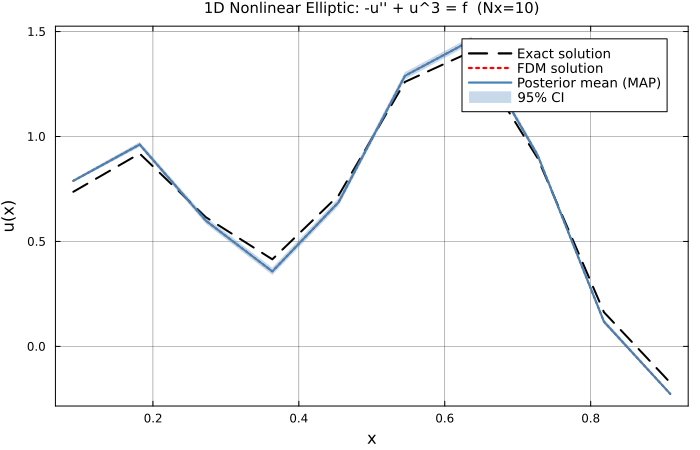

Saved!

Errors:
  FDM: 0.057687
  MAP: 0.057714
  max std: 0.009069


In [24]:
# ============================================================
# 可視化
# ============================================================
p = plot(x_all, u_star;
    label="Exact solution", lw=2, ls=:dash, color=:black,
    xlabel="x", ylabel="u(x)",
    title="1D Nonlinear Elliptic: -u'' + u^3 = f  (Nx=$(Nx))",
    titlefontsize=10, legendfontsize=9,
    grid=true, gridalpha=0.3, framestyle=:box, size=(700,450))
plot!(p, x_all, u_fdm;
    label="FDM solution", lw=2, ls=:dot, color=:red)
plot!(p, x_all, mu_post;
    label="Posterior mean (MAP)", lw=2, color=:steelblue)
plot!(p, x_all, mu_post .+ 1.96 .* std_post;
    lw=0, fillalpha=0, label=false, color=:steelblue)
plot!(p, x_all, mu_post .- 1.96 .* std_post;
    lw=0, fillrange=mu_post .+ 1.96 .* std_post,
    fillalpha=0.3, linealpha=0, label="95% CI", color=:steelblue)
display(p)
savefig(p, "nonlinear_elliptic_1d.png")
println("Saved!")

println("\nErrors:")
println("  FDM: $(round(maximum(abs.(u_fdm   - u_star)), digits=6))")
println("  MAP: $(round(maximum(abs.(mu_post  - u_star)), digits=6))")
println("  max std: $(round(maximum(std_post), digits=6))")


  FDM Newton converged at iter 5

=== Marginal likelihood table (σf=1.477570229043262 fixed) ===
l \ C       0.001      0.0072     0.052      0.37       2.7        19.0       140.0      1000.0     
----------------------------------------------------------------------------------------------------
0.001       -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      
0.0072      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      
0.052       -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      -27.7      
0.37        -27.6      -27.6      -27.6      -27.6      -27.6      -27.6      -27.6      -27.6      
2.7         -579.8     -579.8     -579.7     -579.7     -579.4     -577.3     -562.5     -470.5     
19.0        -188531.8  -188436.9  -187756.2  -182957.1  -152969.5  -52639.3   -1806.8    -352.3     
140.0       -3.54715249e7-3.30030312e7-2.04262515e7-1.987413e6-37398.7   -17012.1   -6691.4    

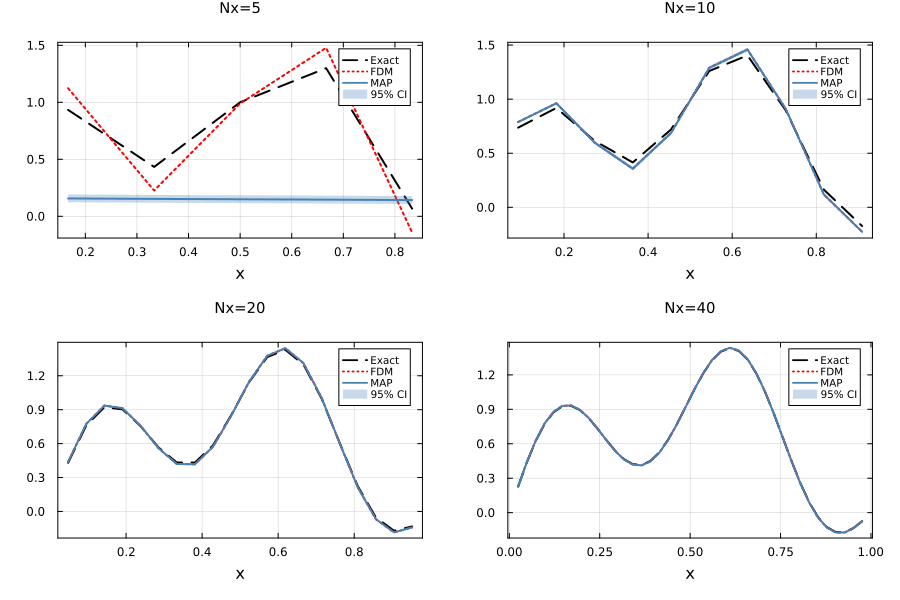

In [25]:
# ============================================================
# Nx sweep
# ============================================================
Nx_list = [5, 10, 20, 40]
plots_sweep = []

for nx in Nx_list
    dxx, xa, Nt = make_grid_1d(nx)
    u_st  = u_true.(xa)
    f_a   = zeros(Nt)
    f_a[2:end-1] = f_rhs.(xa[2:end-1])
    u_fd  = newton_fdm(dxx, nx, f_a)

    sf_fix = maximum(abs.(u_st[2:end-1]))
    sf, bl, bc, _ = grid_search_1d(f_a, xa, dxx, nx;
                                     tau=tau_fixed, nu_ker=nu_ker, σf_fixed=sf_fix)
    Kp    = Symmetric(kernel_matrix_1d(xa, xa; ν=nu_ker, ℓ=bl, σf=sf) + 1e-8*I)
    u_m   = newton_map(dxx, nx, f_a, Kp; C=bc, tau=tau_fixed)
    mu_p, std_p = laplace_posterior(u_m, dxx, nx, Kp; C=bc, tau=tau_fixed)

    err_fd  = round(maximum(abs.(u_fd - u_st)), digits=5)
    err_map = round(maximum(abs.(mu_p - u_st)), digits=5)
    println("Nx=$(nx): FDM=$(err_fd), MAP=$(err_map), max_std=$(round(maximum(std_p),digits=5))")

    pp = plot(xa, u_st; label="Exact", lw=2, ls=:dash, color=:black,
              xlabel="x", title="Nx=$(nx)", titlefontsize=10,
              legendfontsize=7, grid=true, framestyle=:box)
    plot!(pp, xa, u_fd;  label="FDM",  lw=2, ls=:dot,  color=:red)
    plot!(pp, xa, mu_p;  label="MAP",  lw=2, color=:steelblue)
    plot!(pp, xa, mu_p .+ 1.96.*std_p; lw=0, fillalpha=0, label=false, color=:steelblue)
    plot!(pp, xa, mu_p .- 1.96.*std_p; lw=0,
          fillrange=mu_p .+ 1.96.*std_p, fillalpha=0.3, linealpha=0,
          label="95% CI", color=:steelblue)
    push!(plots_sweep, pp)
end

fig_sweep = plot(plots_sweep...; layout=(2,2), size=(900,600), margin=5*Plots.mm)
display(fig_sweep)
savefig(fig_sweep, "nonlinear_elliptic_1d_sweep.png")
println("Saved!")
